## Redes Convolucionales
#### Ejemplo clasificación de perros y gatos para CAPTCHA

Este notebook utiliza datos de la [competición de Kaggle Dogs vs. Cats](https://www.kaggle.com/c/dogs-vs-cats/overview). En esta competicion se utiliza Asirra (Animal Species Image Recognition for Restricting Access), CAPTCHA que sirve para diferenciar entre una persona o una máquina accediendo a una página web. Este tipo de "pruebas" se utilizan para evitar emails de spam, y ataques por fuerza bruta contra servidores.

En este notebook vamos a probar que hay técnicas de clasificado automáticas de imágenes mediante redes neuronales, que con las que se intenta saltar CAPTCHA

# Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import load_img
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import random
import os

# Define Constants
Tendremos una serie de constantes como las dimensiones de las imágenes, que serán fijas a lo largo de todo el notebook

In [2]:
IMAGE_WIDTH=100
IMAGE_HEIGHT=100
IMAGE_CHANNELS=3
IMAGE_SIZE=(IMAGE_WIDTH, IMAGE_HEIGHT, IMAGE_CHANNELS)
BATCH_SIZE = 32
EPOCHS = 25

# Prepare Training Data
1. Descárgate el dataset
2. Descomprime el dataset y guardalo en la ruta que quieras del ordenador.
3. En este punto vamos guardar en una lista las etiquetas de cada foto.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
!ls /content/drive/MyDrive/data_dogs_cats/

PROF_test1.zip	PROF_train.zip


In [5]:
import zipfile
import os

ruta_zip = "/content/drive/MyDrive/data_dogs_cats/PROF_train.zip"          # Ruta del ZIP
#destino = "carpeta_destino" # Carpeta donde se extraerá

# Crear carpeta destino si no existe
# os.makedirs(destino, exist_ok=True)

with zipfile.ZipFile(ruta_zip, 'r') as zip_ref:
    zip_ref.extractall()

print("Descompresión de train completada.")


Descompresión de train completada.


In [6]:
ruta_zip = "/content/drive/MyDrive/data_dogs_cats/PROF_test1.zip"          # Ruta del ZIP
#destino = "carpeta_destino" # Carpeta donde se extraerá

# Crear carpeta destino si no existe
# os.makedirs(destino, exist_ok=True)

with zipfile.ZipFile(ruta_zip, 'r') as zip_ref:
    zip_ref.extractall()

print("Descompresión de test completada.")

Descompresión de test completada.


In [7]:
from pathlib import Path

ROOT_PATH = os.getcwd()

#TRAIN_PATH = ROOT_PATH + "\\data\\PROF_train\\PROF_train\\train\\"
#TEST_PATH = ROOT_PATH + "\\data\\PROF_test1\\PROF_test1\\test1\\"


ruta_base = Path(ROOT_PATH)
carpeta = "PROF_train"
carpeta2 = "train"

TRAIN_PATH = ruta_base / carpeta / carpeta2


#carpeta = "PROF_test1"
carpeta2 = "test1"

#TEST_PATH = ruta_base  / carpeta / carpeta2
TEST_PATH = ruta_base / carpeta2


In [8]:
TRAIN_PATH

PosixPath('/content/PROF_train/train')

In [9]:
TEST_PATH

PosixPath('/content/test1')

In [10]:
num_directorios_train = len([f for f in TRAIN_PATH.iterdir() if f.is_file()])
print(num_directorios_train, "fotos de train")



25000 fotos de train


In [11]:
num_directorios_test = len([f for f in TEST_PATH.iterdir() if f.is_file()])
print(num_directorios_test, "fotos de test")

12500 fotos de test


### See Total In count

In [12]:
num_gatos = len(list(TRAIN_PATH.glob('cat*')))
num_perros = len(list(TRAIN_PATH.glob('dog*')))

print(f"Gatos: {num_gatos}")
print(f"Perros: {num_perros}")

Gatos: 12501
Perros: 12501


# See sample image

In [13]:
from skimage.io import imread
import cv2

(239, 320, 3)
255


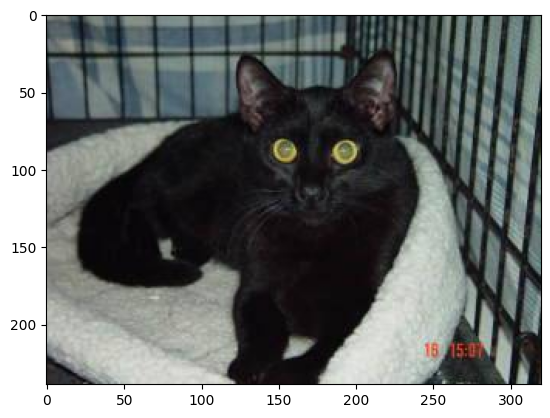

In [14]:
filenames = os.listdir(TRAIN_PATH)
sample = random.choice(filenames)
image = imread(TRAIN_PATH / sample)

print(image.shape)
print(np.max(image))
plt.imshow(image);

Una imagen no es mas que un array de HxWxC píxeles, siendo H(Height) y W(Width) las dimensiones de resolución de la imagen, y C el número de canales. Habrá tres valores por píxel.

array([[[118, 125, 118],
        [120, 127, 120],
        [121, 128, 121],
        ...,
        [124, 146, 134],
        [120, 144, 130],
        [124, 148, 134]],

       [[121, 127, 123],
        [123, 130, 123],
        [124, 130, 126],
        ...,
        [124, 146, 134],
        [120, 144, 130],
        [123, 147, 133]],

       [[125, 131, 129],
        [127, 133, 129],
        [127, 133, 131],
        ...,
        [124, 146, 134],
        [119, 143, 129],
        [120, 144, 130]],

       ...,

       [[ 47,  43,  42],
        [ 48,  44,  43],
        [ 49,  45,  46],
        ...,
        [ 20,  19,  17],
        [ 31,  27,  24],
        [ 59,  55,  52]],

       [[ 43,  39,  38],
        [ 45,  41,  40],
        [ 46,  42,  43],
        ...,
        [ 17,  17,  15],
        [ 33,  29,  28],
        [ 67,  63,  60]],

       [[ 41,  37,  36],
        [ 43,  39,  38],
        [ 45,  41,  42],
        ...,
        [ 14,  14,  12],
        [ 36,  32,  31],
        [ 74,  70,  67]]], shape=(239, 320, 3), dtype=uint8)
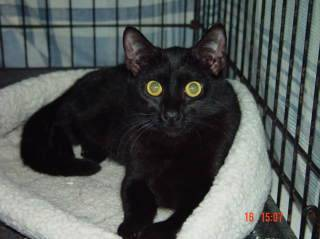

In [15]:
image

# Resize image
Cargar todas las imágenes a la vez es un problema ya que son un total de 25000 (unos 500MB la carpeta de train). Este proceso require mucha memoria, por lo que tendremos que aplicarle un resize a cada imagen para bajarlas de resolución. Esto también nos sirve para solventar el problema de tener imágenes con distintas resoluciones.

Tamaño imagen original: (375, 499, 3)
Tamaño imagen reshape: (100, 100, 3)


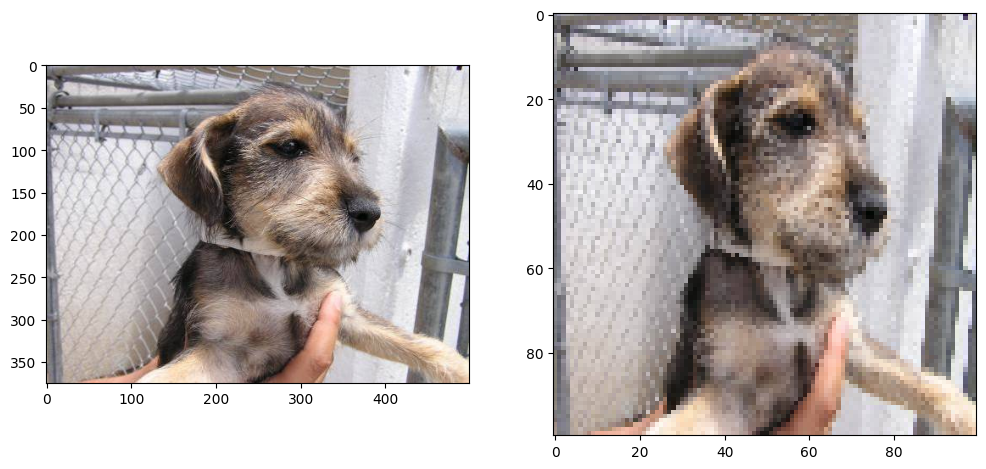

In [16]:
plt.figure(figsize=(12, 12))

sample = random.choice(filenames)
image = imread(TRAIN_PATH / sample)
imagesmall = cv2.resize(image, (IMAGE_WIDTH, IMAGE_HEIGHT))

print("Tamaño imagen original:", image.shape)
print("Tamaño imagen reshape:", imagesmall.shape)

# Original image
plt.subplot(1, 2, 1)
plt.imshow(image)

# Resized image
plt.subplot(1, 2, 2)
plt.imshow(imagesmall);

# Color
Podríamos cargar las imágenes como blanco y negro, de esta forma se reduciría el espacio de features considerablemente al contar con un único canal

Tamaño imagen original: (375, 499)


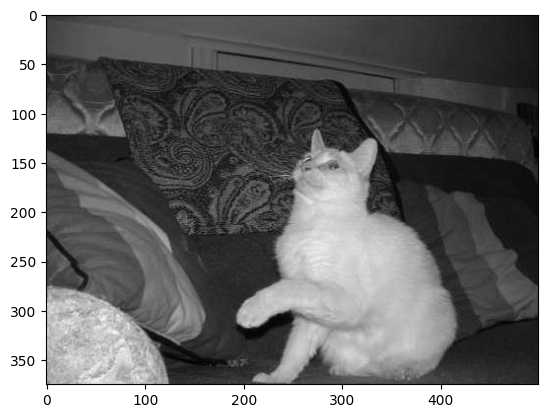

In [17]:
sample = random.choice(filenames)

image = cv2.imread(filename = TRAIN_PATH / sample, flags = cv2.IMREAD_GRAYSCALE)

print("Tamaño imagen original:", image.shape)
plt.imshow(image, cmap='gray');

# Load data
Llega el momento de cargar los datos. Ya no estan sencillo como cuando teníamos datasets en CSVs puesto que ahora hay que cargar miles de archivos en memoria en este notebook. Para ello necesitaremos un programa iterativo que vaya recorriendo los archivos de la carpeta, cargarlos como array de numpy y almacenarlos en un objeto.

In [18]:
import os
import shutil

def reorganizar_dataset(path):
    path = Path(path)
    dog_dir = path / "dog"
    cat_dir = path / "cat"
    dog_dir.mkdir(exist_ok=True)
    cat_dir.mkdir(exist_ok=True)

    for file in path.iterdir():
        if file.is_file():
            category = file.name.split('.')[0]
            if category == "dog":
                shutil.move(str(file), str(dog_dir / file.name))
            elif category == "cat":
                shutil.move(str(file), str(cat_dir / file.name))

reorganizar_dataset("PROF_train/train") # en PROF_train/train creo las carpetas dog y cat y muevo ahí las fotos



In [19]:
import tensorflow as tf

my_dataset = tf.keras.utils.image_dataset_from_directory(
    "PROF_train/train",
    image_size=(IMAGE_WIDTH, IMAGE_HEIGHT),
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True
)


Found 25000 files belonging to 2 classes.


In [20]:
# Validación
dataset_size = my_dataset.cardinality().numpy()
val_size = int(dataset_size * 0.2)
train_size = dataset_size - val_size

train_ds = my_dataset.take(train_size)
val_ds = my_dataset.skip(train_size)

In [21]:
# prefetch acelera
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

# Build Model

<img src="https://i.imgur.com/ebkMGGu.jpg" width="100%"/>

* **Conv Layer**: extraerá diferentes features de las imagenes
* **Pooling Layer**: Reduce las dimensiones de las imágenes tras una capa convolucional
* **Fully Connected Layer**: Tras las capas convolucionales, aplanamos las features y las introducimos como entrada de una red neuronal normal.
* **Output Layer**: Las predicciones de la red

Para el loss y la metrica, se puede usar un binary_crossentropy, al ser un target binario. O

In [22]:
from tensorflow import keras
from tensorflow.keras.optimizers import RMSprop

In [23]:


layers = [
    keras.layers.Input(shape=IMAGE_SIZE),
    keras.layers.Rescaling(1./255),

    keras.layers.Conv2D(32, (3,3), activation='relu'),
    keras.layers.Conv2D(32, (3,3), activation='relu'), # (100, 100, 3)
    keras.layers.MaxPooling2D(pool_size=(2,2)),

    keras.layers.Conv2D(64, (3,3), activation='relu'),
    keras.layers.MaxPooling2D(2,2),
    keras.layers.Conv2D(128, (3,3), activation='relu'),
    keras.layers.MaxPooling2D(2,2),
    keras.layers.Conv2D(128, (3,3), activation='relu'),
    keras.layers.MaxPooling2D(2,2),
    keras.layers.Flatten(),
    keras.layers.Dense(512, activation='relu'),
    keras.layers.Dense(1, activation='sigmoid')

]

model = keras.Sequential(layers)

model.compile(optimizer = RMSprop(learning_rate=1e-4),
             loss = 'binary_crossentropy',
             metrics = ['accuracy'])


In [24]:

# kernel 3x3  3 canales 1 bias  32 filtros
((3*3*3) + 1) * 32

896

In [25]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 98, 98, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 96, 96, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 46, 46, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 21, 21, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,299,681 (4.96 MB)

 Trainable params: 1,299,681 (4.96 MB)

 Non-trainable params: 0 (0.00 B)

# Callbacks
#### Early Stopping

In [26]:
from keras.callbacks import EarlyStopping
earlystop = EarlyStopping(patience=5)

In [27]:
from keras.callbacks import ModelCheckpoint
mcheckpoint = ModelCheckpoint("callback_model.keras")

# Fit the model

In [28]:
history = model.fit(train_ds,
         validation_data=val_ds,
         epochs = EPOCHS,
         batch_size = BATCH_SIZE,
         callbacks = [earlystop, mcheckpoint],
         validation_split = 0.2,
         verbose=1)


Epoch 1/25
626/626 ━━━━━━━━━━━━━━━━━━━━ 57s 71ms/step - accuracy: 0.5881 - loss: 0.6665 - val_accuracy: 0.6188 - val_loss: 0.6423
Epoch 2/25
626/626 ━━━━━━━━━━━━━━━━━━━━ 38s 61ms/step - accuracy: 0.6847 - loss: 0.5893 - val_accuracy: 0.7291 - val_loss: 0.5433
Epoch 3/25
626/626 ━━━━━━━━━━━━━━━━━━━━ 36s 57ms/step - accuracy: 0.7413 - loss: 0.5230 - val_accuracy: 0.7661 - val_loss: 0.4900
Epoch 4/25
626/626 ━━━━━━━━━━━━━━━━━━━━ 38s 60ms/step - accuracy: 0.7717 - loss: 0.4765 - val_accuracy: 0.7848 - val_loss: 0.4672
Epoch 5/25
626/626 ━━━━━━━━━━━━━━━━━━━━ 36s 58ms/step - accuracy: 0.7969 - loss: 0.4396 - val_accuracy: 0.8086 - val_loss: 0.4242
Epoch 6/25
626/626 ━━━━━━━━━━━━━━━━━━━━ 40s 57ms/step - accuracy: 0.8159 - loss: 0.4056 - val_accuracy: 0.8263 - val_loss: 0.3977
Epoch 7/25
626/626 ━━━━━━━━━━━━━━━━━━━━ 37s 59ms/step - accuracy: 0.8319 - loss: 0.3774 - val_accuracy: 0.8231 - val_loss: 0.3939
Epoch 8/25
626/626 ━━━━━━━━━━━━━━━━━━━━ 35s 56ms/step - accuracy: 0.8434 - loss: 0.3557 - 

Lo guardamos.

In [29]:
model.save("mi_modelo.keras")


Lo cargamos.

In [30]:

model = keras.models.load_model("mi_modelo.keras")

# Evaluate
Probemos los datos en el conjunto de test.

In [31]:

def cargar_imagen(ruta, image_size=(100,100)):
    img = tf.keras.utils.load_img(ruta, target_size=image_size)
    img_array = tf.keras.utils.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)  # (1, 100, 100, 3)
    return img_array


In [32]:
img = cargar_imagen("test1/1.jpg", image_size=IMAGE_SIZE)

pred = model.predict(img)[0][0]


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


In [33]:
pred

np.float32(0.98884857)

In [34]:
carpeta = "test1"
contador = 0

for archivo in os.listdir(carpeta):
    ruta = os.path.join(carpeta, archivo)
    img = cargar_imagen(ruta, IMAGE_SIZE)
    pred = model.predict(img)[0][0]

    clase = "perro 🐶" if pred > 0.5 else "gato 🐱"
    print(f"{archivo}: {clase} (score={pred:.3f})")

    contador += 1

    if contador == 50:
      break



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
11819.jpg: gato 🐱 (score=0.000)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
5850.jpg: gato 🐱 (score=0.276)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
5500.jpg: gato 🐱 (score=0.000)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
6369.jpg: gato 🐱 (score=0.000)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
11871.jpg: perro 🐶 (score=0.857)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
617.jpg: perro 🐶 (score=0.999)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
5964.jpg: gato 🐱 (score=0.000)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
9451.jpg: gato 🐱 (score=0.000)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
3692.jpg: gato 🐱 (score=0.094)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
6620.jpg: perro 🐶 (score=0.987)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
8052.jpg: gato 🐱 (score=0.001)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
3266.jpg: gato 🐱 (score=0.000)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
4462.jpg: gato 🐱 (score=0.004)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
2143.jpg: perro 🐶 (score=0.991)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4

Matriz de confusión

In [35]:
train_ds_confusion_matrix = tf.keras.utils.image_dataset_from_directory(
    "PROF_train/train",
    image_size=(IMAGE_WIDTH,IMAGE_HEIGHT),
    batch_size=BATCH_SIZE,
    shuffle=False,
    label_mode="binary"
)



Found 25000 files belonging to 2 classes.


In [36]:
y_true = np.concatenate([y for x, y in train_ds_confusion_matrix], axis=0)
y_pred = model.predict(train_ds_confusion_matrix)
y_pred = (y_pred > 0.5).astype(int)


782/782 ━━━━━━━━━━━━━━━━━━━━ 22s 27ms/step


In [37]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)
print(cm)


[[12060   440]
 [ 1171 11329]]


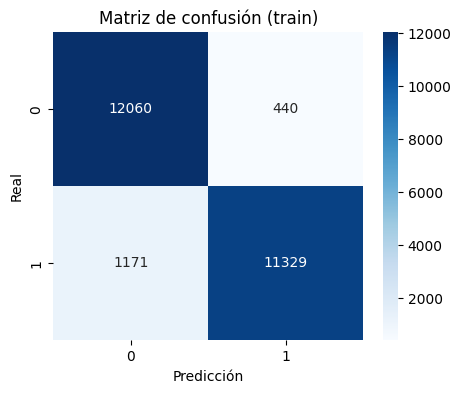

In [38]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión (train)")
plt.show()

In [39]:
(11685+11681)/(11685+11681+815+819)

0.93464

# Image data generator

In [40]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    shear_range=0.1,
    zoom_range=0.2,
    horizontal_flip=True,
    width_shift_range=0.1,
    height_shift_range=0.1,
    validation_split=0.1   # 10% para validación
)

val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.1
)


In [41]:
train_generator = train_datagen.flow_from_directory(
    "PROF_train/train",
    target_size=(100, 100),
    batch_size=32,
    class_mode="binary",
    subset="training"
)


Found 22500 images belonging to 2 classes.


In [42]:
val_generator = val_datagen.flow_from_directory(
    "PROF_train/train",
    target_size=(100, 100),
    batch_size=32,
    class_mode="binary",
    subset="validation",
    shuffle=False
)


Found 2500 images belonging to 2 classes.


In [43]:
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10
)


Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 115s 159ms/step - accuracy: 0.5025 - loss: 0.7000 - val_accuracy: 0.4944 - val_loss: 0.6903
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 98s 140ms/step - accuracy: 0.5487 - loss: 0.6858 - val_accuracy: 0.5620 - val_loss: 0.6775
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 97s 138ms/step - accuracy: 0.5914 - loss: 0.6649 - val_accuracy: 0.6328 - val_loss: 0.6441
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 98s 139ms/step - accuracy: 0.6215 - loss: 0.6447 - val_accuracy: 0.6320 - val_loss: 0.6447
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 100s 142ms/step - accuracy: 0.6483 - loss: 0.6276 - val_accuracy: 0.6472 - val_loss: 0.6215
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 98s 139ms/step - accuracy: 0.6618 - loss: 0.6121 - val_accuracy: 0.7020 - val_loss: 0.5764
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 99s 140ms/step - accuracy: 0.6764 - loss: 0.5987 - val_accuracy: 0.7084 - val_loss: 0.5642
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 99s 140ms/step - accuracy: 0.6889 - loss:

In [44]:
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10
)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 102s 145ms/step - accuracy: 0.7207 - loss: 0.5490 - val_accuracy: 0.7420 - val_loss: 0.5155
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 105s 149ms/step - accuracy: 0.7272 - loss: 0.5382 - val_accuracy: 0.7708 - val_loss: 0.4770
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 102s 144ms/step - accuracy: 0.7328 - loss: 0.5314 - val_accuracy: 0.7628 - val_loss: 0.4798
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 101s 144ms/step - accuracy: 0.7402 - loss: 0.5186 - val_accuracy: 0.7832 - val_loss: 0.4590
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 104s 148ms/step - accuracy: 0.7480 - loss: 0.5103 - val_accuracy: 0.7640 - val_loss: 0.4807
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 107s 152ms/step - accuracy: 0.7552 - loss: 0.5004 - val_accuracy: 0.7988 - val_loss: 0.4340
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 103s 146ms/step - accuracy: 0.7621 - loss: 0.4899 - val_accuracy: 0.7520 - val_loss: 0.4849
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 104s 148ms/step - accuracy: 0.7677 -

In [45]:
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=5
)

Epoch 1/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 101s 143ms/step - accuracy: 0.7856 - loss: 0.4577 - val_accuracy: 0.8244 - val_loss: 0.3861
Epoch 2/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 101s 144ms/step - accuracy: 0.7860 - loss: 0.4487 - val_accuracy: 0.8116 - val_loss: 0.3937
Epoch 3/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 104s 147ms/step - accuracy: 0.7925 - loss: 0.4415 - val_accuracy: 0.8164 - val_loss: 0.3958
Epoch 4/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 105s 149ms/step - accuracy: 0.7982 - loss: 0.4355 - val_accuracy: 0.8316 - val_loss: 0.3688
Epoch 5/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 103s 146ms/step - accuracy: 0.7971 - loss: 0.4312 - val_accuracy: 0.8168 - val_loss: 0.3908


In [46]:
val_eval_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.1
)

val_eval_generator = val_eval_datagen.flow_from_directory(
    "PROF_train/train",
    target_size=(100, 100),
    batch_size=32,
    class_mode="binary",
    subset="validation",
    shuffle=False
)


Found 2500 images belonging to 2 classes.


In [47]:


y_true = val_eval_generator.classes
y_pred = (model.predict(val_eval_generator) > 0.5).astype(int).ravel()


79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 71ms/step


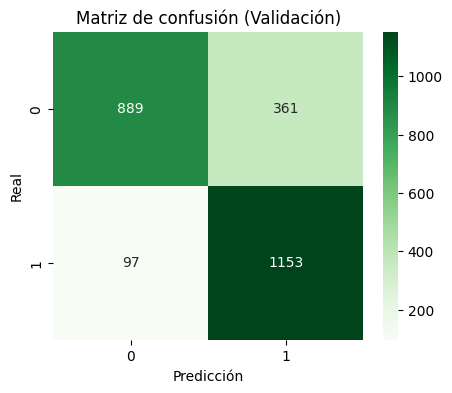

In [48]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión (Validación)")
plt.show()


In [49]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array


def mostrar_augmentations(ruta_imagen, image_size=(100,100), n_imagenes=12):
    # 1. Cargar imagen original
    img = load_img(ruta_imagen, target_size=image_size)
    x = img_to_array(img)
    x = np.expand_dims(x, axis=0)  # (1, h, w, 3)

    # 2. Definir augmentación
    datagen = ImageDataGenerator(
        rescale=1./255,
        rotation_range=15,
        shear_range=0.1,
        zoom_range=0.2,
        horizontal_flip=True,
        width_shift_range=0.1,
        height_shift_range=0.1
    )

    # 3. Crear generador
    gen = datagen.flow(x, batch_size=1)

    # 4. Mostrar n imágenes aumentadas
    plt.figure(figsize=(12, 6))
    for i in range(n_imagenes):
        batch = next(gen)[0]  # tomar la imagen del batch
        plt.subplot(3, 4, i+1)
        plt.imshow(batch)
        plt.axis("off")
    plt.suptitle("Variaciones aumentadas de la imagen", fontsize=14)
    plt.show()


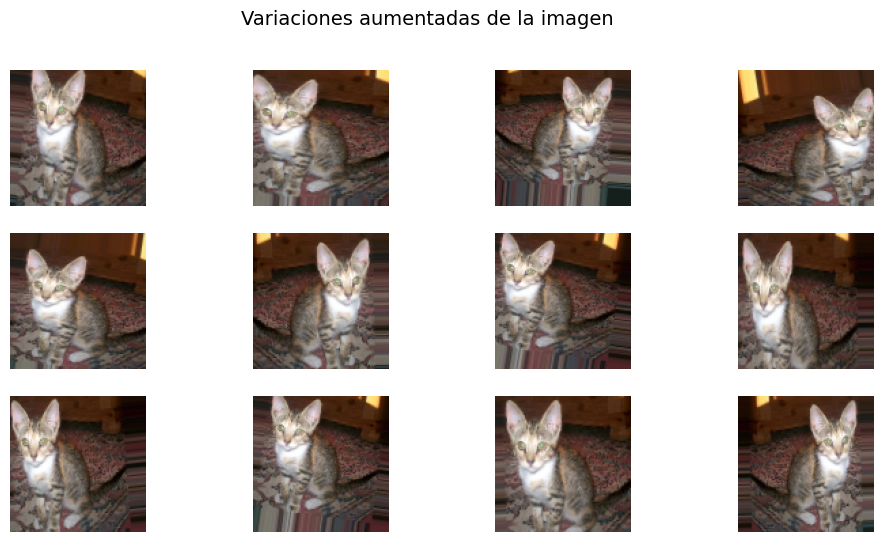

In [50]:
mostrar_augmentations("PROF_train/train/cat/cat.7.jpg", image_size=(100,100), n_imagenes=12)


In [51]:
model.save("modelo_aumentado.keras")

Guardamos los archivos importantes en nuestro Google Drive para no perderlos

In [52]:
import os

SAVE_PATH = '/content/drive/MyDrive/Proyecto_Gatos_Perros'

os.makedirs(SAVE_PATH, exist_ok=True)

In [53]:
model.save(f'{SAVE_PATH}/callback_model.keras')
model.save(f'{SAVE_PATH}/mi_modelo.keras')
model.save(f'{SAVE_PATH}/modelo_aumentado.keras')

Comprobamos que se ha guardado

In [54]:
os.listdir(SAVE_PATH)

['callback_model.keras', 'mi_modelo.keras', 'modelo_aumentado.keras']